# Lecture 4: Data Preprocessing

In this lecture, we will focus on the principles behind data cleaning and data preparation, which will be done largely through plotting the data (matplotlib), manipulating the data (pandas, numpy), and splitting the data into testing and learning sets in preparation for more advanced analysis tools like machine learning (Scikit-Learn). Our aim is to combine all of these steps into a data manipulation pipeline for easy handling.

This is the very first step in your machine learning experience: data manipulation and feature engineering represent 80% of the machine learning workflow. Applying algorithms only comes at the end, and is only meaningful if the data has been treated properly. 

In this particular case study, our goal will be to predict the porosity of marine sediments based on the colour and the natural gamma-ray variation in each core. 

As mentioned, the first step of every data processing pipeline is to prepare the data for machine learning. This includes several steps:
1. Eliminate duplicate rows in the data
2. Split the dataset into multiple subsets (typically, a training and a test set). 
3. Explore our training data and find potential co-variance, and decide on what features to include, or even to create new features from existing ones.
4. Clean the data and impute missing values
5. Normalise/standardise your data
6. Ultimately, you want to create a data pipeline to streamline the preparation process, including all preparation steps. This way you can apply the same pipeline to multiple datasets, for instance, your test set or your unknown data.

Let's get started!

## Learning Objectives
1. Practice your Pandas, Numpy and Matplotlib skills
2. Handle missing data
3. Transform data into new features
4. Split datasets into stratified subsets
5. Build data preparation pipelines

## 4.0 Introduction to Data Preparation
<a id="intro"></a>

In [45]:
from IPython.display import IFrame
display(IFrame('https://youtube.com/embed/YKRzY9oKwU8', width = 640, height = 360))

## 4.1 Getting to know your data

The first step will always be to load our data, and get to know it. Here, I am giving you data from five ODP/IODP expedition:
* ODP Leg 194, Marion Plateau, NE Australia
* IODP Exp 317, Canterbury Basin, New Zealand
* IODP Exp 342, Newfoundland Margin, North Atlantic
* IODP Exp 359, Maldives, Indian Ocean
* IODP Exp 372, Hikurangi Subduction Margin, New Zealand

The dataset merges porosity measurements with natural gamma ray and sediment color data:

1. porosity : the measurement of porosity was done on the ship using the MADs approach: moisture and density are measured by evaporating a cube of sediment. The difference in weight represents the amount of water trapped in the sediment, wich is then transformed into a porosity value.
2. Natural Gamma Ray : this contains high-resolution measurements of natural gamma radiation of the sediment, a function largely of clay content. The value given in the dataset is the total counts or `NGR total counts (cps)`
3. Color : the measurements from a colorimetric track that is reported in the [L* a* b* color scale](https://en.wikipedia.org/wiki/CIELAB_color_space), where L* is luminocity, and a* and *b are the color axis. The nice thing about the L* a* b* color scale (as opposed to the RGB scale) is that the lightness (luminosity) and actual color values are separate properties.

The files also contain of course a full ODP/IODP sample reference in terms of expedition number, site number, hole, core, section, and top interval sampled (in the `label` series - see supplemental exercise in Lecture 2 to learn how to do that), as well as the depth in meters where the sample was taken (`Depth CSF-A (m)`).

Today, our aim is to prepare this data so that in the next session we can train a number of machine learning algorithms to predict porosity based on the other parameters we have at hand. With a succesful algorithm we should be able to predict a reasonable porosity value in sediments with a reasonable uncertainty.

First, let's import our favorite libraries, pandas and numpy:


In [46]:
# Your code here
import pandas as pd
import numpy as np

Now let's have a look at the porosity data for Expedition 317:

In [47]:
data = pd.read_csv('Datasets/core_data.csv')
data.head()

,label,Depth CSF-A (m),Porosity (vol%),NGR total counts (cps),Reflectance L*,Reflectance a*,Reflectance b*
0,317-U1351A-001H-1-0.265,0.26,57.0,23.219,43.0,-2.5,10.1
1,342-U1409A-001H-1-0.26,0.26,79.9,20.350,53.4,1.5,1.9
2,342-U1409A-001H-1-0.26,0.26,79.9,20.350,53.4,1.5,1.9
3,342-U1408A-001H-1-0.37,0.37,64.1,23.010,47.9,3.2,6.1
4,342-U1407A-001H-1-0.38,0.38,54.9,24.460,51.3,4.7,8.4


Let's see how many data rows and columns we have:

In [48]:
data.shape

(5542, 7)

## 4.2 Duplicates

There don't *appear* to be any issues with the data above. We have 5542 measurements of porosity, gamma ray, and the color characteristics of the sediment (the `L*`, `a*`, and `b*` scale). One of the things we need to do early on in the preparation process is to split our data. The goal of splitting our dataset is to ensure that we don't use the same set of data to *train* and *test* our model. Consequently, the two sets that we'll be splitting our data into are known as the training set and the test set, respectively.

In the same vein, duplicates in our data (i.e., having the same *record* more than once in the dataset) are a problem: if we split a dataset with duplicates, we might end up with the same record in both our training and test sets. This is known as 'data leakage': in other words, our test set is no longer independent from the training set that we will use to optimise our algorithm.

Are there any duplicates in our data? Test this yourself by calling the `.duplicated()` function on your dataset ([see documentation here](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html)) and taking the sum of the resulting series:

In [8]:
# Your code here


If you have played with the `duplicated()` function you will have seen that it returns a series of either `True` or `False` statements, and because `True = 1` and `False = 0` when we take the `sum()` of the series, we can use the `.sum()` method to obtain the number of duplicates in the dataset (501 here!).

We now need to get rid of the duplicates, which can easily be done using the `drop_duplicates()` function of Pandas ([see documentation here](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop_duplicates.html)). However, be careful: many Pandas functions (including `drop_duplicates()` return a new dataframe and do not modify the original dataframe in place (we  encountered this behaviour in Lecture 2). Here, we want to modify data in place to avoid having a lot of variable names. So, either reassign the return value of the function to `data`, or use the `inplace = True` option as described in the documentation:

In [49]:
# Your code here
data.drop_duplicates(inplace = True)

Now check if you removed all duplicates (find the number of duplicates in the new `data` dataframe):

In [10]:
#Your code here

## 4.3 Splitting the dataset into a training and a test set

In [11]:
from IPython.display import IFrame
display(IFrame('https://youtube.com/embed/aOAiJtNs-4Q', width = 640, height = 360))

When you train a machine learning algorithm, you're essentially 'fitting' it to a dataset. In other words, you are attempting to find the best parameters for your machine learning algorithm such that the input(s) that you feed into the model will return you the correct output *most of the time*. 

The issue with that is that if you want to test how well your model is doing, you'll need to have set aside a dataset that was **NOT** used to train the model, but that is similar to the training data. If you test your trained model on the <u>training set</u>, your model will have a high degree of accuracy; however, this is **misleading**, since your model is effectively 'overfitting' on your training data (more about this in a later class).

The solution around this is to reserve a portion of the data, for example 30% of the dataset (less for large datasets), for testing - this is the *test set*. The model will be trained on the remaining 70% of data, known as the training set. This means that your algorithm will not have seen any of the data in the test set, and thus cannot be 'overfitted' to this particular data. That said, you'll want your sampling to be statistically meaningful so that both the training set (70% of your data in most cases) and your test set (30% of the data) are representative of the overall distribution of all your samples.

### Sci-kit Learn

In order to do this, we'll be using a new library here called `scikit-learn`. Scikit-learn is a machine learning library but it also includes a lot of data preparation utilities, and we will use those in this lecture.

For our first foray into scikit-learn (which uses the `sklearn` alias), we will import the `train_test_split` function from the `model_selection` module of `sklearn` and create two new data sets: the `train_set` and the `test_set`. Here we go:

In [50]:
from sklearn.model_selection import train_test_split

# This will give you 70% of the data in the training set, and 30% in the test set.
train_set, test_set = train_test_split(data, train_size=0.7, random_state = 30)

***N.B. Note about `random_state`***: the `random_state` paramater is optional. It sets the random seed of pseudo-random algorithm so that the split (or any random operation) is reproducible each time you run the code (or on different machines). In other words, setting `random_state = 30` means that the data will be split exactly the same way on any computer as long as you use the number `30` when calling the `random_state` parameter. You can, of course, set it to any value you want. Indeed, many computer science courses use 42, mostly because many programmers are fans of the **Hitchhiker's Guide to the Galaxy**.

In this case, however, we're going to use `30` because of some learning points later in this chapter.

In [51]:
# Let's look at the training set
train_set.head()


,label,Depth CSF-A (m),Porosity (vol%),NGR total counts (cps),Reflectance L*,Reflectance a*,Reflectance b*
5090,359-U1468A-108X-1-0.54,835.84,43.4,8.226,56.50,2.80,4.80
4393,194-1195B-047X-3-0.47,442.22,33.5,32.800,50.31,-0.65,8.41
4331,359-U1471A-050X-CC-0.09,422.89,43.6,9.880,52.30,2.80,6.10
4584,194-1197B-048R-2-1.23,504.73,32.9,21.800,56.31,0.16,10.52
2160,372-U1517C-021F-3-1.3,120.98,48.7,38.237,43.75,0.96,0.17


You can see that we've randomly sampled a bunch of data by looking at the Index - we now have a random collection of records rather than the original dataset. 

However, remember that we want the train_set and the test_set to have the same data distribution as the entire dataset. So let's compare the distribution of values of the `Depth CSF-A (m)` variable in all of the datasets:

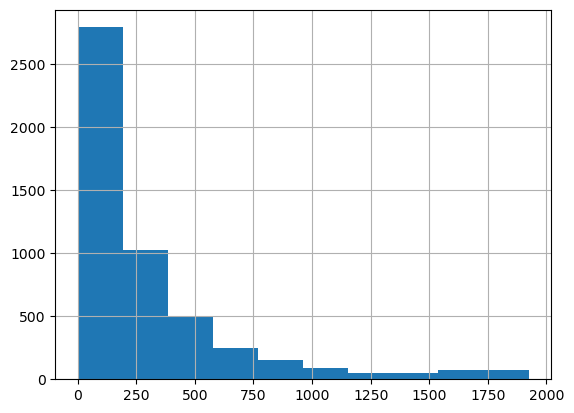

In [14]:
data["Depth CSF-A (m)"].hist();

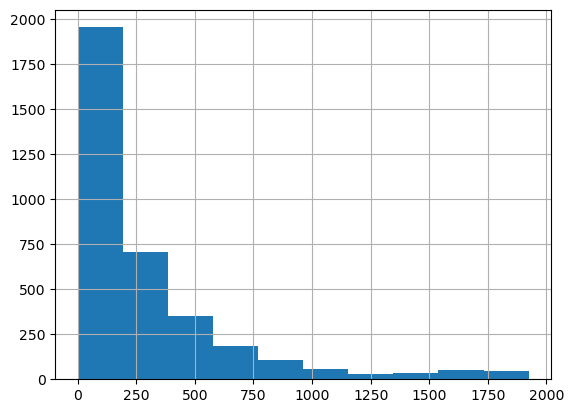

In [15]:
train_set["Depth CSF-A (m)"].hist();

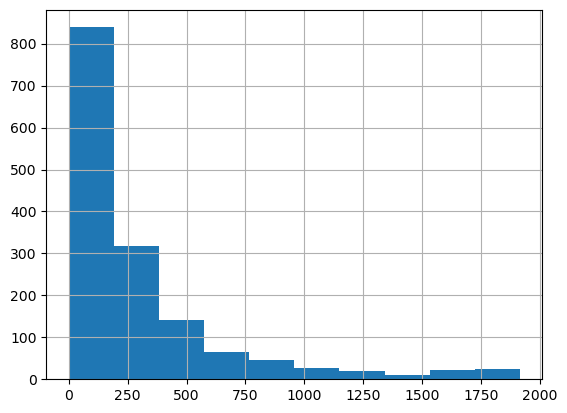

In [16]:
test_set["Depth CSF-A (m)"].hist();

This looks reasonably similar! We can now proceed with the rest of the data preparation. From now on, everything we will do we will do on the `train_set`. We will **NOT** use the `test_set` to make any decisions about our data preparation or our future machine learning preparation (next week).

# 4.4 Handling missing values and outliers

Now that we have split our dataset into a training and a testing set (and we know that there are no duplicates in it), we can continue with our data exploration and preparation. You may not have realized it, but you've just learned an extremely important concept of data preparation for machine learning: apart from dropping duplicates, we do *nothing* to the data before it is split. 

In fact, you shouldn't even peek at the total distribution (I cheated above for illustrative purposes), and no data cleanup operations. Why? Ultimately, we want to use our final model on unknown data - consequently, we'll have to train it under the same conditions: on unknown data. Thus, we need to make sure that the cleaning processes applied and trained on the training set return the appropriate results when applied to the test set: this is the only way we can ensure we have a solid approach to data preparation for unknown samples.

At this stage, it is always a good idea to plot the data and see what it contains. For instance, we can look at some histograms of data distribution:

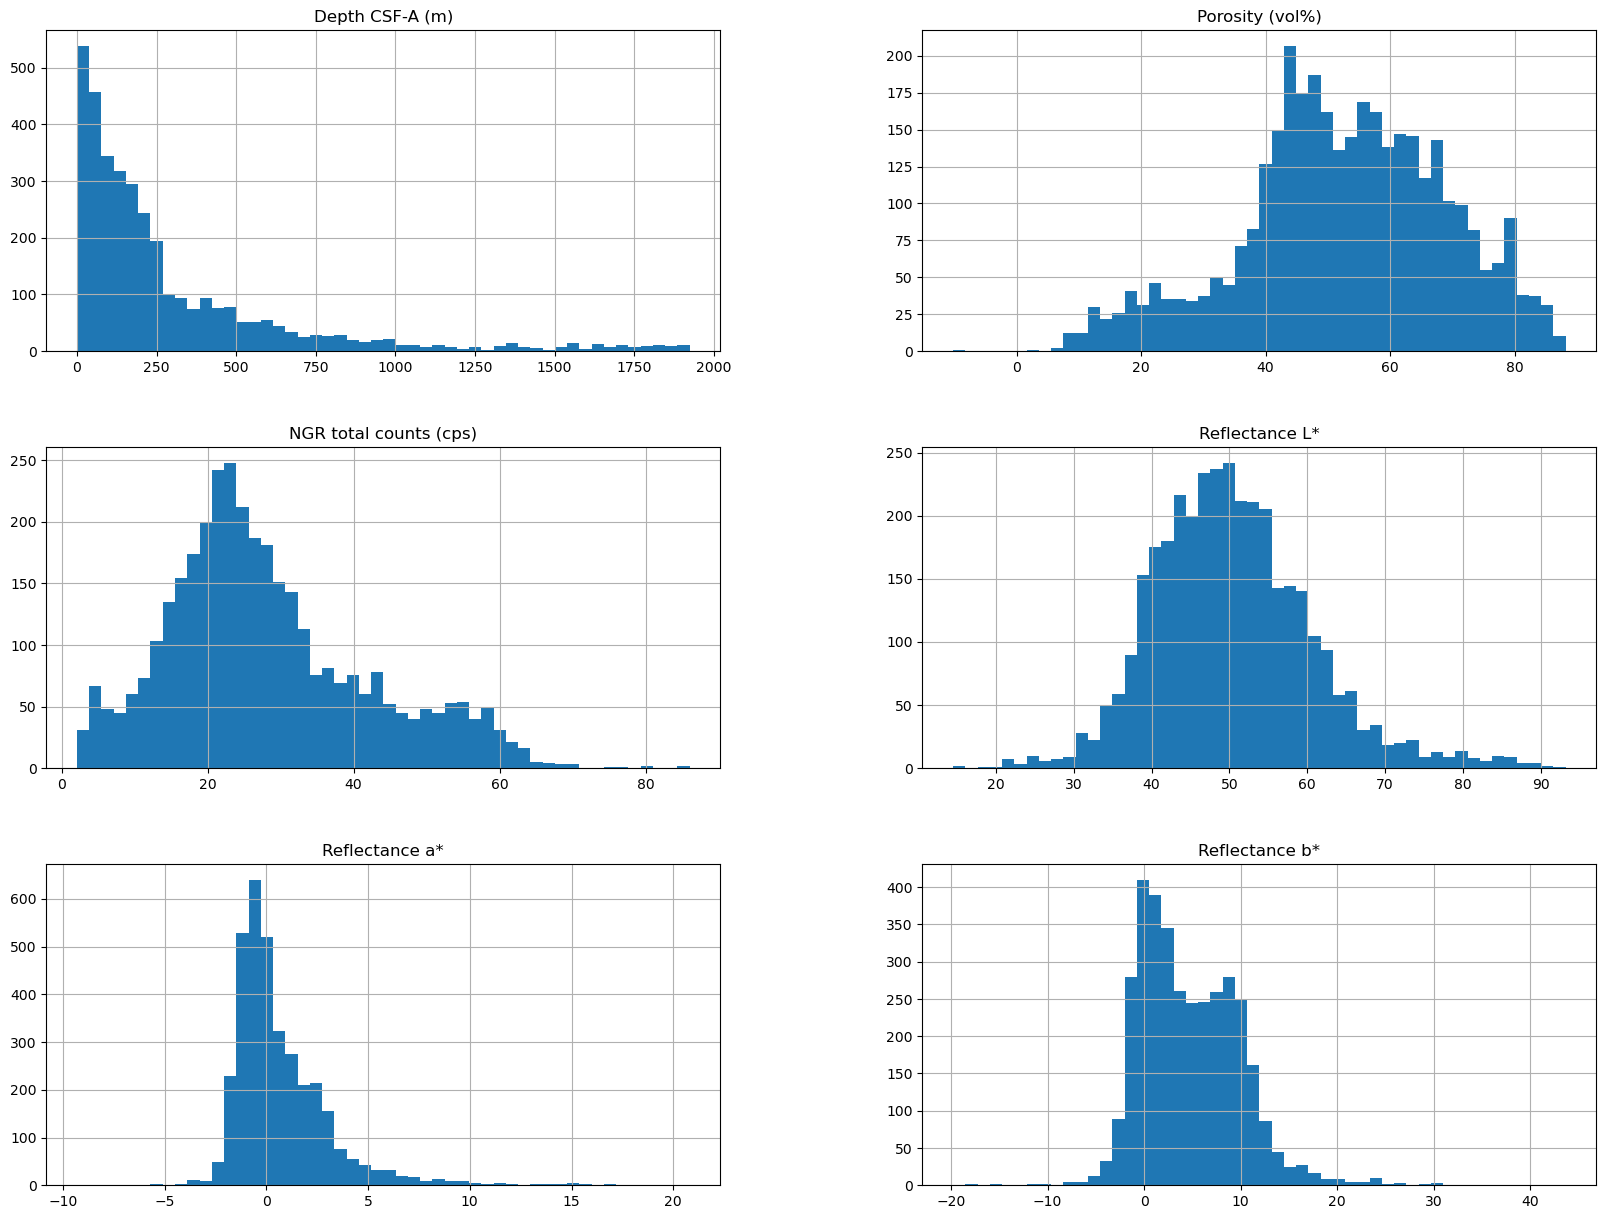

In [52]:
import matplotlib.pyplot as plt
train_set.hist(bins=50, figsize=(20,15));

What we learn from that is that not all of our data is equal. For example, `Reflectance L*` looks like a relatively well-distributed Gaussian curve (i.e., what you would call a 'normal' distribution). `Reflectance b*` also seems relatively normal but potentially has two peaks (i.e., a bimodal distribution). One very obviously strange outlier is the `NRG total counts`, which appears to have a single peak very close to zero, but can apparently extend to very large negative values (more about this later). `Refectlance a*` seems to be slightly skewed, with a few data points below -1 and most of the data above 1 (you would describe this as having a very long tail). Similarly, `Porosity` has a relatively long tail on the lower end, while `Depth` is completely non-parametric and very skewed to the lower depth. This is relatively intuitive: all wells penetrate the surface of the sediments, but only a few wells go deeper than 500 m.

This step is important, as it gives us an overall feel for the data. For instance, if you wanted to predict porosity solely based on depth, we have a problem: we have many more observations at shallower depth than at deeper depth. Thus, any trained algorithm will be skewed to shallower burial trends.

The next step is to look at the summary statistics. Recalling your lecture on Pandas, get the summary statistics on the `train_set` DataFrame below:

In [53]:
# Your Code Here
train_set.describe()

,Depth CSF-A (m),Porosity (vol%),NGR total counts (cps),Reflectance L*,Reflectance a*,Reflectance b*
count,3528.000000,3528.000000,3522.000000,3518.000000,3522.000000,3528.000000
mean,297.485018,52.508768,28.157248,50.417490,0.720905,4.735854
std,367.656318,16.489478,13.876919,10.306791,2.454430,5.377889
min,0.260000,-10.200000,2.107000,14.500000,-9.300000,-19.800000
25%,67.425000,42.800000,18.810000,43.400000,-0.800000,0.700000
50%,166.710000,52.900000,25.400000,49.510000,0.040000,4.000000
75%,378.505000,64.300000,35.656750,56.277500,1.700000,8.492500
max,1924.030000,88.200000,86.038000,93.200000,20.800000,43.700000


Look carefully at the minimum values for the `Porosity`: what can you say about this value? If you think that this is physically impossible, you would be right! In other words, we have some serious outliers!

We will see now how to handle this.

## 4.4.1 Handling Outliers and Missing Data

Data is imperfect. Sometimes, measurements are missing, or they are invalid. You should have seen above from the summary statistics that the minimum value of `NGR total counts` is -9999, which is an impossible value; similarly, porosity has a minimum value of -10.2% (also impossible). For NGR and other physical measurements, very large negative values often represent missing values. In contrast, for porosity, the negative value could indicate a measurement that went wrong.

There are several strategies we can use to handle outliers or missing values. The simplest strategy is to simply delete the missing value. Let's do that for the values of porosity and NGR that are less than zero. First for porosity:

In [54]:
train_set.drop(index = train_set[train_set['Porosity (vol%)']<0].index, inplace = True)

Notice how we set the `index` parameter to be the index of the records with porosity < 0% (`data[data['Porosity (vol%)']<0].index`); this makes it such that the `.drop()` function only drops the specified values. We also specify `inplace = True` to ensure the operation is done in place. 

Another way of doing this would be the following:

```python
train_set = train_set[train_set['Porosity (vol%)'] > 0]
```

Let's check to make sure that everything went correctly by finding the minimum porosity value of our adjusted `train_set`:

In [55]:
train_set['Porosity (vol%)'].min()

1.9

All good! Now your turn: drop all of the rows where the NGR value is negative. Make sure to do this in place.

In [21]:
# Your Code


## Missing Data

Now let's check the data again:

In [56]:
train_set.describe()

,Depth CSF-A (m),Porosity (vol%),NGR total counts (cps),Reflectance L*,Reflectance a*,Reflectance b*
count,3527.000000,3527.000000,3521.000000,3517.000000,3521.000000,3527.000000
mean,297.539712,52.526548,28.160573,50.419257,0.721053,4.737367
std,367.694094,16.457960,13.877487,10.307723,2.454762,5.377900
min,0.260000,1.900000,2.107000,14.500000,-9.300000,-19.800000
25%,67.410000,42.800000,18.810000,43.400000,-0.800000,0.700000
50%,166.840000,52.900000,25.400000,49.520000,0.040000,4.000000
75%,378.730000,64.300000,35.659000,56.280000,1.700000,8.495000
max,1924.030000,88.200000,86.038000,93.200000,20.800000,43.700000


If you did it right, this line of code tells you that you have a mean porosity of 52.51%, a minimum of 1.9%, and a maximum of 88.2%. Remember, these are water-loaded, uncompacted sediments, so this is not a particularly surprising distribution. However, one thing we need to check is if all of the values in the data table are numbers. One common issue is when you have missing data in your file: Pandas will treat them as 'Not a Number', also represented with the value `NaN`. 

The `NaN` values do not appear in the table above as they are automatically filtered out by pandas in summative operations. But you can use the `.isna()` method to find `NaN` values in your dataframe. `isna()` works just like `duplicated()`. So use it here on the `train_set` DataFrame to check if there are any `NaN` values and where these are:

In [23]:
# Your code here


If you have done this correctly, we now have 10 `L*` and 6 `a*` values missing. You can check this by running:

In [24]:
train_set.isnull().sum()

label                      0
Depth CSF-A (m)            0
Porosity (vol%)            0
NGR total counts (cps)     6
Reflectance L*            10
Reflectance a*             6
Reflectance b*             0
dtype: int64

One way to handle missing values is to replace them with an estimated value. This is called **imputation**.

There is no universal percentage of missing data below which imputation is always appropriate. The choice depends on how much data is missing, why it is missing, and what the variable represents.

In this lecture, we will practise replacing missing values with the mean, median or most frequent value. We calculate these values using the **training set only**, then use the same values to fill missing entries in the test set.

### Using `.fillna()`

Perhaps the simplest way is to use a `.fillna()` method that can fill the missing value for us with a value of our choice.

In [57]:
# We can use the '.fillna()' methods to replace the NaN values with a number. In this case, 0:
filled_df = train_set.fillna(0)
filled_df.isnull().sum()

label                     0
Depth CSF-A (m)           0
Porosity (vol%)           0
NGR total counts (cps)    0
Reflectance L*            0
Reflectance a*            0
Reflectance b*            0
dtype: int64

Replacing missing values with zero is appropriate only when zero has a meaningful interpretation for that variable. Otherwise, it introduces artificial measurements.

Two common alternatives are the mean and median of the observed training values. However, neither method preserves the original distribution: adding repeated values at the mean or median can reduce variability and change relationships between variables. Imputed values are estimates, not new measurements.


In [60]:
# Calculate the median using the training data only.
median = train_set["Reflectance L*"].median()

# Work on a copy so that train_set remains unchanged.
filled_df = train_set.copy()

# Fill missing values and assign the result back to the column.
filled_df["Reflectance L*"] = (
    filled_df["Reflectance L*"].fillna(median)
)

# Check how many missing values remain in each column.
filled_df.isna().sum()

label                     0
Depth CSF-A (m)           0
Porosity (vol%)           0
NGR total counts (cps)    6
Reflectance L*            0
Reflectance a*            6
Reflectance b*            0
dtype: int64

In [62]:
# Calculate the mean using the training data only.
mean = train_set["Reflectance L*"].mean()

# Start again from train_set to compare mean and median imputation.
filled_df = train_set.copy()

# Fill missing values and assign the result back to the column.
filled_df["Reflectance L*"] = (
    filled_df["Reflectance L*"].fillna(mean)
)

# Check how many missing values remain in each column.
filled_df.isna().sum()

label                     0
Depth CSF-A (m)           0
Porosity (vol%)           0
NGR total counts (cps)    6
Reflectance L*            0
Reflectance a*            6
Reflectance b*            0
dtype: int64

Great, so we now know how to fill our `NaN` values. But remember that we've split our dataset into a train set and a test set. How are we going to change the data in the test set? Remember, we want to do the same thing to the test_set as we did to the train_set in order to ensure that we repeat the same steps to prepare our testing data as we did our training data. The solution would be to save the mean (or median) value of each property from the training set and apply this to the data in the test set, or indeed to any new unknown data. But this is cumbersome, since we have to remember a value for each statistical quantity and store it somewhere...

Let's look at how to do this automatically and easily...

## 4.4.2 Using sklearn imputers

Manually imputing data with `.fillna()` is not very practical. Instead, data scientists use an `Imputer` class from the scikit-learn library. An `Imputer` has the following jobs:
1. To compute a property on the training set. This can be the mean, median, max, etc... of your training data.
2. To then fill the `NaN` values in the dataset with this property. This can be on the training set, the test set, or any set of new unknown data you want to use for predictions - you just need to provide the `Imputer` with the input.
3. To retain this data whenever you need it. The idea is to train and save your Imputer object, and use the same trained object throughout your code.

The `Imputer` object belongs to a type of class known as a **transformer**. Transformers play an important role in dealing with data in `sklearn` (usually by manipulating it in some way) and have similar methods as predictor classes, i.e., machine learning algorithms. The following methods are typically used by transformers (and by extension, predictors):

* `.fit()`: this trains a model or an imputer on the data. For an `Imputer`, `.fit()` causes your object to find the value of the chosen property (the mean, median, etc...).
* `.transform()`: takes a dataset as an argument, and returns a new, transformed dataset. In the case of imputers, the new dataset has their `NaNs` replaced by the imputed value calculated by `.fit()`.
* `.fit_transform()`: as the name suggests, does both `.fit()` and `.transform()` in a single operation

Here is an example in practice:

In [63]:
# Import the class:
from sklearn.impute import SimpleImputer

# Create the imputer object - here, our chosen property is the 'mean' of the data
imputer = SimpleImputer(strategy='mean') 

# Now let's fit our imputer to the training set. First we find the name of all the numeric columns and store the column name.
# I automatically train the imputer on all the numerical data columns where I have missing values 
# Then we fit the imputer. Remember, this 'trains' the imputer:
num_cols = data.select_dtypes(include = 'number').columns
imputer.fit(train_set[num_cols]) 

# Now we can apply it to our train set to replace the values with NaNs:
train_set[num_cols] = imputer.transform(train_set[num_cols])

Let's check if it worked:

In [29]:
train_set.isna().sum()

label                     0
Depth CSF-A (m)           0
Porosity (vol%)           0
NGR total counts (cps)    0
Reflectance L*            0
Reflectance a*            0
Reflectance b*            0
dtype: int64

Let's check our `test_set`. Do we have any missing values in there?

In [30]:
test_set.isna().sum()

label                     0
Depth CSF-A (m)           0
Porosity (vol%)           0
NGR total counts (cps)    0
Reflectance L*            1
Reflectance a*            2
Reflectance b*            0
dtype: int64

Sure enough, there are missing values in our `test_set`. And of course, in real life, any unknown data that we might want to run our model on may have the same problem! This is where `transformers` shine: we can now apply our `SimpleImputer` object to the `test_set` (or any unknown dataset) as the first step of a data preparation pipeline:

In [31]:
test_set[num_cols] =  imputer.transform(test_set[num_cols])

In [32]:
test_set.isna().sum()

label                     0
Depth CSF-A (m)           0
Porosity (vol%)           0
NGR total counts (cps)    0
Reflectance L*            0
Reflectance a*            0
Reflectance b*            0
dtype: int64

# Exercise 1: Create an imputer using the 'most frequent' value

When I used the following code above:

```python
imputer = SimpleImputer(strategy = "mean")
```

I effectively declared that I wanted to use the standard strategy for imputing data (i.e., replacing all `NaNs` with the mean of each column). In this exercise, I want you to redo what we have done above, but this time create an imputer that replaces the values with the 'most frequent' value. To do this, you will need to:

1. Split the data again. Above I already imputed the data for `train_set` and `test_set` so you need to create these sets again from the original `data` dataframe.
2. Read about how to change the strategy to meet your goals in the [sklearn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html).
3. Create and `.fit()` a new `SimpleImputer()`
4. Apply this new imputer to your new `train_set` and `test_set`

You can do all of this in one cell of code (not one line) if you want (and its actually recommended to try and do it this way!).

In [33]:
# YOUR CODE HERE

## 4.5 Feature Scaling


In [34]:
from IPython.display import IFrame
display(IFrame('https://youtube.com/embed/SieI_0PP5xM', width = 640, height = 360))

One thing we still need to do is to scale our data so that all of the features (i.e., each variable) are at a similar scale. This is because many machine learning algorithms do not deal well with data on different scales. 

For example, the porosity ranges from 0-60%, but depth ranges to values that are two orders of magnitude greater than this: which one do you think an algorithm will see as more significant? Depth, of course. Feature scaling is a big topic and we cannot cover all of it in this class, but I encourage you to look further into it. [Here is for example an article that I like on this topic](https://www.analyticsvidhya.com/blog/2020/04/feature-scaling-machine-learning-normalization-standardization/).

The two choices that we have for feature scaling are 'normalization' and 'standardization'. Normalization is a scaling technique in which values are shifted and rescaled so that they end up ranging between 0 and 1. It is also known in Scikit-learn as *Min-Max scaling*. 

Standardization is another scaling technique where the values in the dataset are manipulated such that the scaled values are centred around a mean of zero with a standard deviation of one. In Scikit-learn, this is known as 'StandardScaler'.

Both of these strategies have their advantages and disadvantages. Normalized values are guaranteed to be between 0 and 1, and some algorithms need this certainty. The StandardScaler does not guarantee that the range of the features will be 0-1 (indeed, it's almost impossible for this to be the case). However, standardization is less susceptible to outliers. Choosing the right strategy often involves a bit of trial and error - indeed, some pipelines try both strategies and to see which works best with the model they have chosen. In practice, many data scientists train their models on raw data, standardized data, and normalized data and pick the best-performing strategy. Of course, this is computationally expensive and represents time that might be better spent on other parts of the analysis.

Let's import the `StandardScaler()` object from `sklearn` and use it to scale all of the numeric columns: 

In [35]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Identify the columns containing numerical features
numerical_columns = train_set.select_dtypes(include = 'number').columns

scaler.fit(train_set[numerical_columns])

### You may have to do the following depending on your version of pandas
# Making a copy above to avoid warnings in the next line of code 
# See https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
# train_set = train_set.copy()

train_set[numerical_columns] = scaler.transform(train_set[numerical_columns])

In [36]:
# Now let's inspect our train set:
train_set.describe()

,Depth CSF-A (m),Porosity (vol%),NGR total counts (cps),Reflectance L*,Reflectance a*,Reflectance b*
count,3.527000e+03,3.527000e+03,3.527000e+03,3.527000e+03,3527.000000,3.527000e+03
mean,6.043743e-18,3.424788e-17,8.763428e-17,-9.770718e-17,0.000000,-8.058324e-17
std,1.000142e+00,1.000142e+00,1.000142e+00,1.000142e+00,1.000142,1.000142e+00
min,-8.086120e-01,-3.076549e+00,-1.879264e+00,-3.490140e+00,-4.086347,-4.563276e+00
25%,-6.259615e-01,-5.910773e-01,-6.738149e-01,-6.820351e-01,-0.620249,-7.508394e-01
50%,-3.555081e-01,2.269451e-02,-1.991223e-01,-7.960419e-02,-0.277717,-1.371300e-01
75%,2.208406e-01,7.154667e-01,5.384148e-01,5.670374e-01,0.399191,6.988165e-01
max,4.424115e+00,2.167857e+00,4.174743e+00,4.156845e+00,8.187718,7.245980e+00


As you can see, all the values have been standardized. The next logical step is to apply this new transformer (the `StandardScaler()` object, which we've assigned to `scaler`) to the test set. However, you can see that manipulating and changing our data requires multiple steps, and each one of these steps needs to be fitted, applied to the train set, and then applied to the test set. Things will even get more crowded when you want to prepare data and apply it all the way to a machine learning model. Wouldn't it be nice if we could assemble all these steps into a single object that we can fit once and apply multiple times? 

Well, we can! Read on to find out how.

# Exercise 2

So far, we've conducted a lot of data preparation on the training set. However, we also need to need to apply this to the test set (as well as to any new set of unknown data). So how are we going to do that? It would be impractical and difficult to do this manually and would be very prone to errors.

Instead, in this exercise you are going to write three functions to do this programmatically:

* `split_dataframe(df)`: this function will take the entire dataframe, remove duplicates, and return two dataframes (a `train_set`, and a `test_set`) 
* `fit_train_parameters(train_set)`: this function will take the `train_set` as an input, and apply all of the imputation and scaling strategies that we've used above. Here, I want you to use a `SimpleImputer` using the mean as your strategy. Once all the missing values have been replaced by the imputer, I want the function to scale the data using a normalization strategy. Read about the `MinMaxScaler()` class in `Sklearn` and use it on your data. The function should return a tuple containing the **trained** imputer and scaler objects.
* `transform_data(parameters, df)` will impute and scale any data (`df`) passed to it. The `parameters` argument should take the tuple of imputer and scaler objects and apply them to the passed dataframe.

If you've done everything correctly, the entire workflow of this lecture will be shortened to the following:

```python
data = pd.read_csv('Datasets/core_data.csv')
train_set, test_set = split_dataframe(data)
parameters = fit_train_parameters(train_set)
train_set = transform_data(parameters, train_set)
test_set = transform_data(parameters, test_set)
```

Have fun!

First, let's reload a clean version of the dataset:

In [37]:
data = pd.read_csv('Datasets/core_data.csv')

In [38]:
# Your Code here

def split_dataframe(df):
    pass
    
def fit_train_parameters(train_set):
    pass
    
def transform_data(parameters, df):
    pass
    

**Bonus Task**: There is one step that we took in the data preparation workflow above that we did not reproduce here. What did we miss out? Can you create another function to resolve this issue? Where should it go in our pipeline?

## 4.6 Data Preparation Pipelines

Hopefully **Exercise 2** has shown you that keeping track of all of the objects you use in your transformation can become a headache. To help with this, scikit-learn gives us the option to use the `Pipeline()` class, which allows us to chain transformers (`Transformer()` objects) and predictors (`Model()` objects; i.e., machine learning algorithms) into what is known as a 'data preparation pipeline'. Once trained, a pipeline can be used to systematically apply your data preparation steps in a consistent manner to any sort of dataset, thus avoiding a lot of headaches associated with remembering variables.


In [39]:
from IPython.display import IFrame
display(IFrame('https://youtube.com/embed/VSGTHhUqIk4', width = 640, height = 360))

You can learn much more about the [pipeline class from the documentation available on the sklearn website](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html). In essence, `Pipeline()` objects are used as follows:

1. Create a Pipeline instance using a **list of tuples**.
2. Each tuple contains 
    - a. the name (a string) of the transformer
    - b. the transformer object itself
3. Fit the entire pipeline to your data
4. You can then either apply your pipeline to other data or predict (see next lecture) on new data using your pipeline.

As a way of example, here is pseudo-code to create a pipeline, fit it, and apply it:

```python

from sklearn.pipeline import Pipeline

my_pipeline = Pipeline([
        ('transformer1', Transformer()), # This is called a 'step' in the preparation pipeline
        ('transformer2', Transformer()), # Anything you give to the pipeline will be transformed by transformer1, 
                                         # then transformer2, then the std_scaler
        ('std_scaler', StandardScaler())
    ])

# Now we can train our pipeline, or 'fit' it
my_pipeline.fit(train_data)

# And this is how I would transform my test_set
test_data = my_pipeline.transform(test_data)
```

Let's try running the above Pipeline and see what comes out:

In [40]:
from sklearn.pipeline import Pipeline

my_pipeline = Pipeline([
        ('imputer', SimpleImputer()), 
        ('std_scaler', StandardScaler())
    ])

my_pipeline

Pipeline(steps=[('imputer', SimpleImputer()), ('std_scaler', StandardScaler())])

You'll notice that by running the above cell, Jupyter creates a little widget that shows what's in the pipeline. This makes it easy to visualize what your pipeline will be doing to your data.

Let's apply this Pipeline to some data.

In [64]:
# Reload the data and remove duplicates.
data = pd.read_csv("Datasets/core_data.csv").drop_duplicates()

# Create fresh training and test sets.
train_set, test_set = train_test_split(
    data, train_size=0.7, random_state=30
)

numeric_columns = train_set.select_dtypes(include="number").columns

# Learn preprocessing parameters from the training set only.
train_set[numeric_columns] = my_pipeline.fit_transform(
    train_set[numeric_columns]
)

# Apply the same parameters to the test set.
test_set[numeric_columns] = my_pipeline.transform(
    test_set[numeric_columns]
)

display(train_set.isna().sum())
display(train_set.head())

label                     0
Depth CSF-A (m)           0
Porosity (vol%)           0
NGR total counts (cps)    0
Reflectance L*            0
Reflectance a*            0
Reflectance b*            0
dtype: int64

,label,Depth CSF-A (m),Porosity (vol%),NGR total counts (cps),Reflectance L*,Reflectance a*,Reflectance b*
5090,359-U1468A-108X-1-0.54,1.464496,-0.552477,-1.437715,0.591068,0.847920,0.011929
4393,194-1195B-047X-3-0.47,0.393725,-1.152945,0.334899,-0.010445,-0.559098,0.683292
4331,359-U1471A-050X-CC-0.09,0.341141,-0.540346,-1.318406,0.182933,0.847920,0.253694
4584,194-1197B-048R-2-1.23,0.563772,-1.189337,-0.458572,0.572605,-0.228755,1.075695
2160,372-U1517C-021F-3-1.3,-0.480150,-0.231014,0.727090,-0.647913,0.097511,-0.849125


You can see that our data has no missing values AND has been standardized!

You can access any element of the pipeline by using the `get_params()` method, which returns a dictionary of the different steps in the pipeline:

```python
my_pipeline.get_params()['std_scaler'] # This returns the StandardScaler() object in the Pipeline
```

Experiment in the cell below to see what parameters our pipeline is using. 

In [42]:
# Your code here

Congratulations, you've learned about a tool that can make things a lot easier for you! That said, it's important to know what Pipelines can and *can't* do. Don't worry: the next Exercise will help you get on your feet.

# Exercise 3

In this exercise, we will repeat what we did in exercise 2 but this time using the `Pipeline` class in `sklearn`. Create a data preparation pipeline that takes your numerical data in the dataframe (ignore the non-numerical data - try to use `data.dtypes`), replace all the `NaNs` with the `mean` values, and normalises your data (i.e. using the `MinMaxScaler()` class). 

Note: the `Pipeline` class can only use `sklearn` Transformer and Model objects - you won't be able to put your `split_dataframe()` function into the Pipeline (it can be done, but is outside of the scope of this course - you can look up how to create custom sklearn Transformers if you're interested!). Instead, you will need to start from the `data` dataframe and redo the `train_test_split` (feel free to reuse your previous functions from Exercise 2) before putting the data in the pipeline. Then apply your pipeline to your new train and test sets.

In [43]:
# Your code here
data = pd.read_csv('Datasets/core_data.csv') 


# Feedback Form

In [44]:
%%html 
<iframe src="https://forms.gle/oFa8tBXYhVUZqt1M9" width="800" height="600" frameborder="0" marginheight="0" marginwidth="0">Loading…</iframe>